# Práctica 04: Gradientes de una imagen y Transformada de Fourier
**Curso:** Visión Computacional
**Docente:** Hans Harley Ccacyahuillca Bejar

**Alumno:** Jean Franco Colque Galindo (193109)

En este notebook está el desarrollo de las dos partes de la práctica:

- **04.01:** implementar cinco métodos diferentes para calcular el gradiente de una imagen.
- **04.02:** aplicar un filtro pasa-altos en el dominio de la frecuencia usando la Transformada de Fourier.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color, img_as_float

plt.rcParams["figure.dpi"] = 72

## 0. Carga de la imagen

La guía recomienda trabajar con una resonancia o una tomografía, así que elegí una **resonancia magnética de abdomen** (corte axial a la altura de los riñones). La saqué de los archivos DICOM de prueba que trae la librería `pydicom` (`MR-SIEMENS-DICOM-WithOverlays.dcm`) y la pasé a PNG para que sea más fácil de cargar. Queda de $484 \times 484$ píxeles.

Primero probé con el fantoma de Shepp-Logan, pero como solo tiene elipses de intensidad constante los resultados no se notaban mucho. En la resonancia en cambio se ven varias estructuras con bordes y texturas distintas: el hígado con una lesión redonda, los dos riñones, la vértebra, la aorta y las asas del intestino. Eso ayuda a comparar mejor los filtros.

La imagen la convierto a tipo **float** en el rango $[0,1]$, como pide la guía, para no tener problemas de desbordamiento cuando hagamos restas o la FFT. El archivo `resonancia_abdomen.png` tiene que estar en la misma carpeta que el notebook.

Tamaño: (484, 484) | tipo: float64 | rango: 0.0 - 1.0


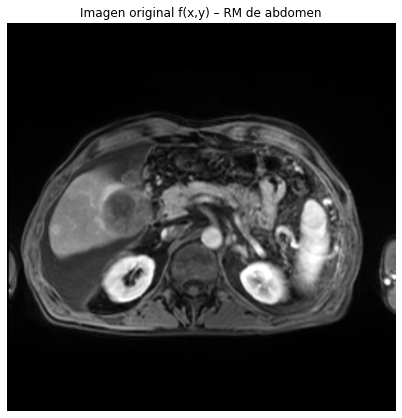

In [2]:
import os

# La imagen debe estar en la MISMA carpeta que este notebook (Practica_4/)
RUTA_IMAGEN = "resonancia_abdomen.png"

def cargar_imagen(ruta):
    if not os.path.exists(ruta):
        raise FileNotFoundError(
            f"No se encontró '{ruta}' en {os.getcwd()}. "
            "Abre el notebook desde la carpeta Practica_4 junto con la imagen.")
    img = io.imread(ruta)
    if img.ndim == 3:
        img = color.rgb2gray(img[..., :3])
    img = img_as_float(img)            # float en el rango [0, 1]
    return img.astype(np.float64)

img = cargar_imagen(RUTA_IMAGEN)
print("Tamaño:", img.shape, "| tipo:", img.dtype, "| rango:", img.min().round(3), "-", img.max().round(3))

plt.figure(figsize=(7, 7)); plt.imshow(img, cmap="gray"); plt.title("Imagen original f(x,y) – RM de abdomen"); plt.axis("off"); plt.show()

# Parte 04.01: Cinco métodos para calcular el gradiente

El gradiente de una imagen $f(x,y)$ es un vector formado por sus derivadas parciales:

$$\nabla f = \begin{bmatrix} G_x \\ G_y \end{bmatrix} = \begin{bmatrix} \dfrac{\partial f}{\partial x} \\[2mm] \dfrac{\partial f}{\partial y} \end{bmatrix}$$

De ahí sacamos la magnitud, que nos dice qué tan fuerte es el borde:

$$|\nabla f| = \sqrt{G_x^2 + G_y^2}$$

y la dirección, que indica hacia dónde cambia la intensidad:

$$\theta = \operatorname{atan2}(G_y,\; G_x)$$

Como la imagen es discreta no podemos derivar directamente, entonces las derivadas se aproximan con máscaras (kernels) $K_x$ y $K_y$ que se pasan sobre la imagen:

$$G_x = f * K_x \qquad G_y = f * K_y$$

Tomé $x$ hacia la derecha (columnas) y $y$ hacia abajo (filas).

### Convolución implementada por nosotros

Para no depender de funciones ya hechas como `cv2.Sobel`, programé la convolución a mano. En vez de recorrer píxel por píxel (que en Python es muy lento), recorro las posiciones del kernel y voy sumando la imagen desplazada multiplicada por cada coeficiente. El resultado es el mismo pero mucho más rápido.

En los bordes repito el valor del píxel más cercano (`mode="edge"`). Para los kernels de tamaño par, como $[-1\;\;1]$, el ancla se pone en la esquina superior izquierda para que el resultado sea justo $f(x+1)-f(x)$.

In [3]:
def correlacion2d(img, kernel):
    # Correlación 2D: salida(y,x) = sum_ij kernel(i,j) * img(y+i-ay, x+j-ax)
    kh, kw = kernel.shape
    ay, ax = (kh - 1) // 2, (kw - 1) // 2          # ancla del kernel
    imgp = np.pad(img, ((ay, kh - 1 - ay), (ax, kw - 1 - ax)), mode="edge")
    salida = np.zeros_like(img)
    for i in range(kh):
        for j in range(kw):
            salida += kernel[i, j] * imgp[i:i + img.shape[0], j:j + img.shape[1]]
    return salida

def convolucion2d(img, kernel):
    # Convolución = correlación con el kernel volteado 180°
    return correlacion2d(img, np.flipud(np.fliplr(kernel)))

def gradiente(img, kx, ky):
    # Las máscaras están escritas como "plantillas" de derivada, por eso se aplican por correlación
    gx = correlacion2d(img, kx)
    gy = correlacion2d(img, ky)
    magnitud = np.sqrt(gx**2 + gy**2)
    direccion = np.arctan2(gy, gx)
    return gx, gy, magnitud, direccion

### Método 1: Diferencias finitas hacia adelante
Es la forma más directa de aproximar la derivada, restando el píxel siguiente menos el actual:
$$G_x = f(x+1,\,y) - f(x,\,y)$$
$$G_y = f(x,\,y+1) - f(x,\,y)$$
$$K_x = \begin{bmatrix} -1 & 1 \end{bmatrix} \qquad K_y = \begin{bmatrix} -1 \\ 1 \end{bmatrix}$$
Es sencilla, pero el resultado queda corrido medio píxel y reacciona bastante al ruido.

### Método 2: Diferencias centrales
Aquí se usa el píxel de adelante y el de atrás, y se divide entre 2:
$$G_x = \dfrac{f(x+1,\,y) - f(x-1,\,y)}{2}$$
$$G_y = \dfrac{f(x,\,y+1) - f(x,\,y-1)}{2}$$
$$K_x = \dfrac{1}{2}\begin{bmatrix} -1 & 0 & 1 \end{bmatrix} \qquad K_y = \dfrac{1}{2}\begin{bmatrix} -1 \\ 0 \\ 1 \end{bmatrix}$$
Como queda centrada en el píxel ya no hay desplazamiento, y el error es de orden $O(h^2)$, o sea más preciso que el método anterior.

### Método 3: Roberts
Usa máscaras de $2 \times 2$ que derivan en diagonal ($45°$ y $135°$):
$$K_x = \begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix} \qquad K_y = \begin{bmatrix} 0 & 1 \\ -1 & 0 \end{bmatrix}$$
$$G_x = f(x,\,y) - f(x+1,\,y+1)$$
$$G_y = f(x+1,\,y) - f(x,\,y+1)$$
Es rápido y marca bien dónde está el borde, pero al usar tan pocos píxeles también es sensible al ruido.

### Método 4: Prewitt
$$K_x = \begin{bmatrix} -1 & 0 & 1 \\ -1 & 0 & 1 \\ -1 & 0 & 1 \end{bmatrix} \qquad K_y = \begin{bmatrix} -1 & -1 & -1 \\ 0 & 0 & 0 \\ 1 & 1 & 1 \end{bmatrix}$$
Es como la diferencia central, pero repetida en 3 filas (o 3 columnas). Eso hace un promedio en la dirección perpendicular y ayuda a bajar el ruido.

### Método 5: Sobel
$$K_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix} \qquad K_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix}$$
Parecido a Prewitt, pero la fila del centro pesa el doble. Se puede separar en dos vectores:
$$K_x = \begin{bmatrix} 1 \\ 2 \\ 1 \end{bmatrix} \cdot \begin{bmatrix} -1 & 0 & 1 \end{bmatrix}$$
donde $[1\;2\;1]^T$ suaviza (parecido a un filtro gaussiano) y $[-1\;0\;1]$ deriva.

In [4]:
KERNELS = {
    "1. Diferencias hacia adelante": (np.array([[-1, 1]], float),
                                      np.array([[-1], [1]], float)),
    "2. Diferencias centrales":      (np.array([[-1, 0, 1]], float) / 2,
                                      np.array([[-1], [0], [1]], float) / 2),
    "3. Roberts":                    (np.array([[1, 0], [0, -1]], float),
                                      np.array([[0, 1], [-1, 0]], float)),
    "4. Prewitt":                    (np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], float),
                                      np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], float)),
    "5. Sobel":                      (np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float),
                                      np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float)),
}

for nombre, (kx, ky) in KERNELS.items():
    print(nombre, "\n Kx =\n", kx, "\n Ky =\n", ky, "\n")

1. Diferencias hacia adelante 
 Kx =
 [[-1.  1.]] 
 Ky =
 [[-1.]
 [ 1.]] 

2. Diferencias centrales 
 Kx =
 [[-0.5  0.   0.5]] 
 Ky =
 [[-0.5]
 [ 0. ]
 [ 0.5]] 

3. Roberts 
 Kx =
 [[ 1.  0.]
 [ 0. -1.]] 
 Ky =
 [[ 0.  1.]
 [-1.  0.]] 

4. Prewitt 
 Kx =
 [[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]] 
 Ky =
 [[-1. -1. -1.]
 [ 0.  0.  0.]
 [ 1.  1.  1.]] 

5. Sobel 
 Kx =
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]] 
 Ky =
 [[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]] 



### Comprobación de la convolución
Para estar seguro de que mi función estaba bien, comparé el resultado de Sobel con `scipy.ndimage.correlate` usando el mismo tipo de borde. El error salió 0, así que la implementación es correcta.

In [5]:
from scipy.ndimage import correlate
kx = KERNELS["5. Sobel"][0]
error = np.abs(correlacion2d(img, kx) - correlate(img, kx, mode="nearest")).max()
print(f"Error máximo vs scipy (Sobel Gx): {error:.2e}")

Error máximo vs scipy (Sobel Gx): 0.00e+00


### Gradiente con los cinco métodos
Aplicamos los cinco pares de máscaras y calculamos la magnitud máxima y media de cada uno.

In [6]:
resultados = {nombre: gradiente(img, kx, ky) for nombre, (kx, ky) in KERNELS.items()}

print(f"{'Método':32s} {'|G| máx':>9s} {'|G| media':>10s}")
for nombre, (gx, gy, mag, th) in resultados.items():
    print(f"{nombre:32s} {mag.max():9.4f} {mag.mean():10.4f}")

Método                             |G| máx  |G| media
1. Diferencias hacia adelante       0.3765     0.0186
2. Diferencias centrales            0.3355     0.0172
3. Roberts                          0.5243     0.0257
4. Prewitt                          1.9142     0.0983
5. Sobel                            2.5771     0.1325


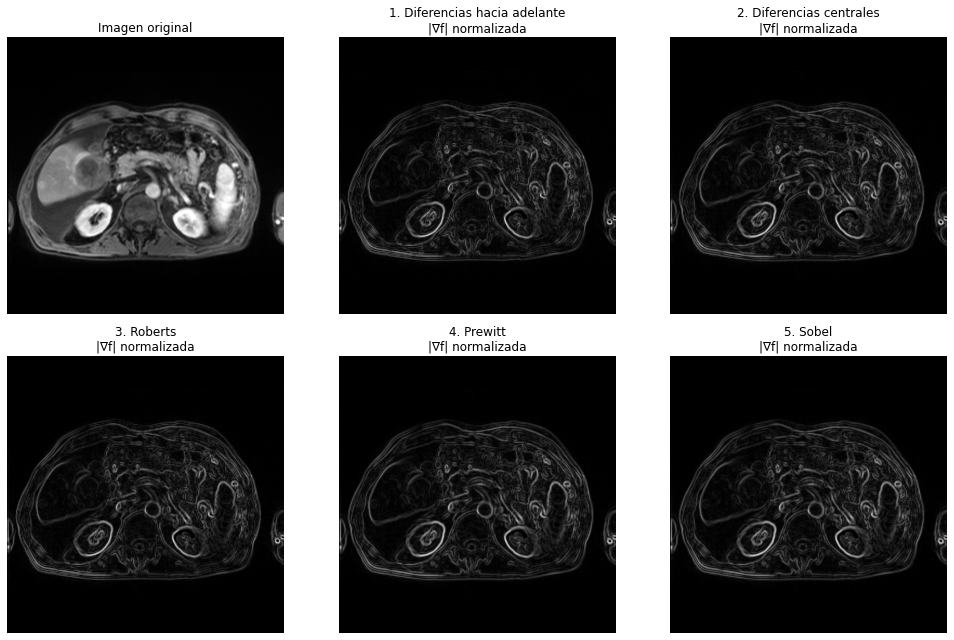

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(14, 9))
ax = ax.ravel()
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Imagen original")
for i, (nombre, (_, _, mag, _)) in enumerate(resultados.items(), start=1):
    ax[i].imshow(mag / mag.max(), cmap="gray")
    ax[i].set_title(f"{nombre}\n|∇f| normalizada")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### $G_x$, $G_y$, magnitud y dirección de cada método
En $G_x$ y $G_y$ el rojo es derivada positiva (pasa de oscuro a claro) y el azul negativa. La dirección $\theta$ solo la pinto donde hay borde, porque en el fondo el ángulo no significa nada.

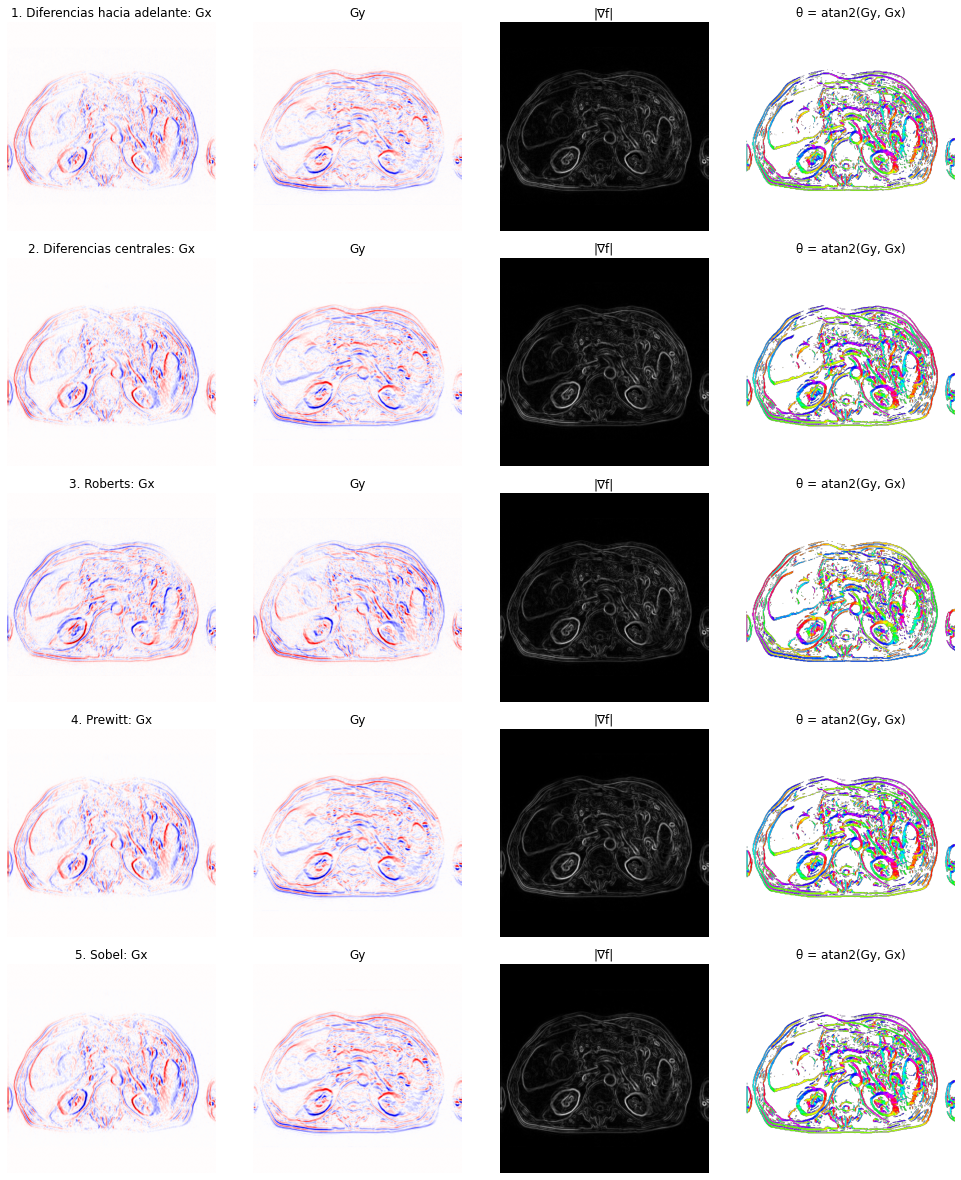

In [8]:
fig, ax = plt.subplots(len(resultados), 4, figsize=(14, 3.3 * len(resultados)))
for f, (nombre, (gx, gy, mag, th)) in enumerate(resultados.items()):
    lim = max(abs(gx).max(), abs(gy).max())
    ax[f, 0].imshow(gx, cmap="seismic", vmin=-lim, vmax=lim); ax[f, 0].set_title(f"{nombre}: Gx")
    ax[f, 1].imshow(gy, cmap="seismic", vmin=-lim, vmax=lim); ax[f, 1].set_title("Gy")
    ax[f, 2].imshow(mag, cmap="gray"); ax[f, 2].set_title("|∇f|")
    ax[f, 3].imshow(np.where(mag > 0.1 * mag.max(), th, np.nan), cmap="hsv", vmin=-np.pi, vmax=np.pi)
    ax[f, 3].set_title("θ = atan2(Gy, Gx)")
    for a in ax[f]: a.axis("off")
plt.tight_layout(); plt.show()

### Perfil de una fila
Para comparar mejor, tomé la fila del centro de la imagen y graficamos la magnitud de cada método. Así se ve qué tan anchos o altos salen los picos en cada borde.

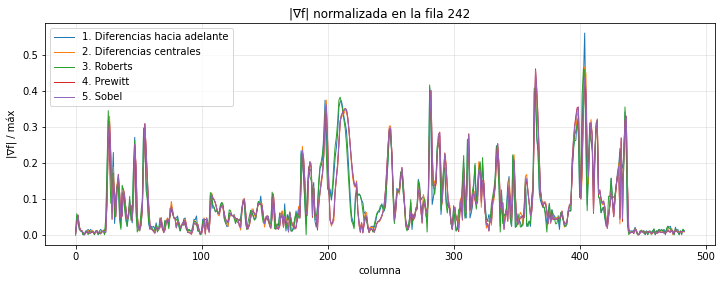

In [9]:
fila = img.shape[0] // 2
plt.figure(figsize=(12, 4))
for nombre, (_, _, mag, _) in resultados.items():
    plt.plot(mag[fila] / mag.max(), label=nombre, lw=1)
plt.title(f"|∇f| normalizada en la fila {fila}")
plt.xlabel("columna"); plt.ylabel("|∇f| / máx"); plt.legend(); plt.grid(alpha=.3); plt.show()

### Prueba con ruido
Para ver qué método aguanta mejor el ruido, le agregué ruido gaussiano con $\sigma = 0.05$ y medí cuánta respuesta aparece en el fondo negro (donde no debería haber bordes), dividido entre la magnitud máxima del borde. Mientras más bajo sale ese número, mejor filtra el ruido.

1. Diferencias hacia adelante    respuesta al ruido relativa = 0.1285
2. Diferencias centrales         respuesta al ruido relativa = 0.0754
3. Roberts                       respuesta al ruido relativa = 0.0964
4. Prewitt                       respuesta al ruido relativa = 0.0481


5. Sobel                         respuesta al ruido relativa = 0.0505


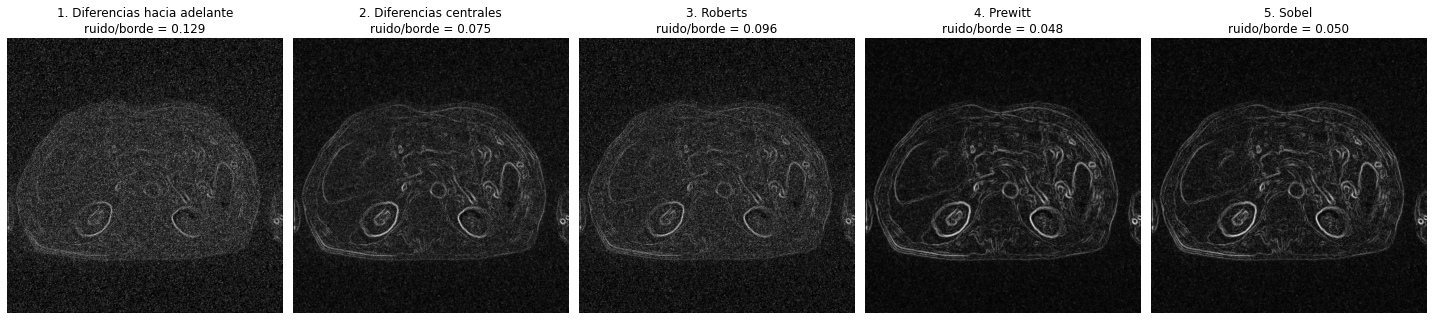

In [10]:
rng = np.random.default_rng(1)
img_ruido = np.clip(img + rng.normal(0, 0.05, img.shape), 0, 1)
fondo = img < 0.02   # zona negra fuera del cuerpo

fig, ax = plt.subplots(1, 5, figsize=(20, 4.5))
for i, (nombre, (kx, ky)) in enumerate(KERNELS.items()):
    _, _, mag_l, _ = resultados[nombre]
    _, _, mag_r, _ = gradiente(img_ruido, kx, ky)
    relacion = mag_r[fondo].mean() / mag_l.max()
    ax[i].imshow(mag_r / mag_r.max(), cmap="gray"); ax[i].axis("off")
    ax[i].set_title(f"{nombre}\nruido/borde = {relacion:.3f}")
    print(f"{nombre:32s} respuesta al ruido relativa = {relacion:.4f}")
plt.tight_layout(); plt.show()

### Análisis de la parte 04.01
- **Diferencias hacia adelante** y **Roberts** solo usan 2 píxeles. Los bordes salen finos y bien ubicados, pero con ruido se ensucian bastante (fueron los que dieron la relación ruido/borde más alta).
- **Diferencias centrales** mejora la precisión y ya no tiene el corrimiento de medio píxel, pero igual no suaviza nada.
- **Prewitt** y **Sobel** son los que mejor resultado dieron. Los bordes salen más gruesos y continuos, con más magnitud, y en la prueba con ruido tuvieron una relación de $\approx 0.05$ frente a $0.13$ de diferencias hacia adelante. Prewitt filtró un poquito más de ruido porque promedia las 3 filas por igual, mientras que Sobel, al darle más peso a la fila central, ubica mejor el borde.
- En la imagen de la dirección $\theta$ se ve que el ángulo siempre es perpendicular al borde y apunta hacia la zona más clara, por ejemplo alrededor de los riñones los colores van dando la vuelta completa.

# Parte 04.02: Filtro pasa-altos en el dominio de la frecuencia

## Fundamento teórico
La **Transformada de Fourier Discreta (TFD)** en 2D, para una imagen de $M \times N$, se define como:

$$F(u,v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} f(x,y)\, e^{-j 2\pi \left( \frac{ux}{M} + \frac{vy}{N} \right)}$$

y para regresar a la imagen se usa la inversa:

$$f(x,y) = \dfrac{1}{MN} \sum_{u=0}^{M-1} \sum_{v=0}^{N-1} F(u,v)\, e^{\,j 2\pi \left( \frac{ux}{M} + \frac{vy}{N} \right)}$$

Lo que hace la TF es pasar la imagen del dominio espacial (píxeles) al dominio de la frecuencia. Básicamente escribe la imagen como una suma de ondas senoidales de distintas frecuencias y orientaciones.

Algunas cosas importantes que usamos en la práctica:

- El término $F(0,0)$ es la componente **DC**, y es la suma de todos los píxeles:
$$F(0,0) = \sum_{x}\sum_{y} f(x,y) = MN \cdot \bar{f}$$
- Las **bajas frecuencias** representan cambios lentos de intensidad (el fondo, zonas parejas).
- Las **altas frecuencias** representan cambios rápidos (bordes, detalles finos y también el ruido).
- Por el **teorema de convolución**, convolucionar en el espacio es lo mismo que multiplicar en frecuencia:
$$f * h \;\longleftrightarrow\; F \cdot H$$
  Entonces para filtrar basta con multiplicar el espectro por una máscara $H(u,v)$.

Los pasos que seguimos son:
1. $F = \text{FFT}(f)$
2. $F_c = \text{fftshift}(F)$
3. $G_c = F_c \cdot H$
4. $G = \text{ifftshift}(G_c)$
5. $g = \operatorname{Re}\left[\text{IFFT}(G)\right]$

## Pasos 1 y 2: FFT, `fftshift` y visualización del espectro

Calculamos la FFT y luego aplicamos `fftshift` para llevar la frecuencia cero al centro. Para verlo usamos $\log\left(1 + |F(u,v)|\right)$ porque el valor del centro es miles de veces más grande que el resto; si lo grafico en escala normal solo se ve un punto en medio y todo lo demás negro (es lo que sale en la segunda imagen).

También comprobé que $F(0,0)$ es igual a $MN$ por la media de la imagen.

F(0,0)           = 35773.627
M·N·media(f)     = 35773.627
|F| máx / |F| mediana = 26059.5


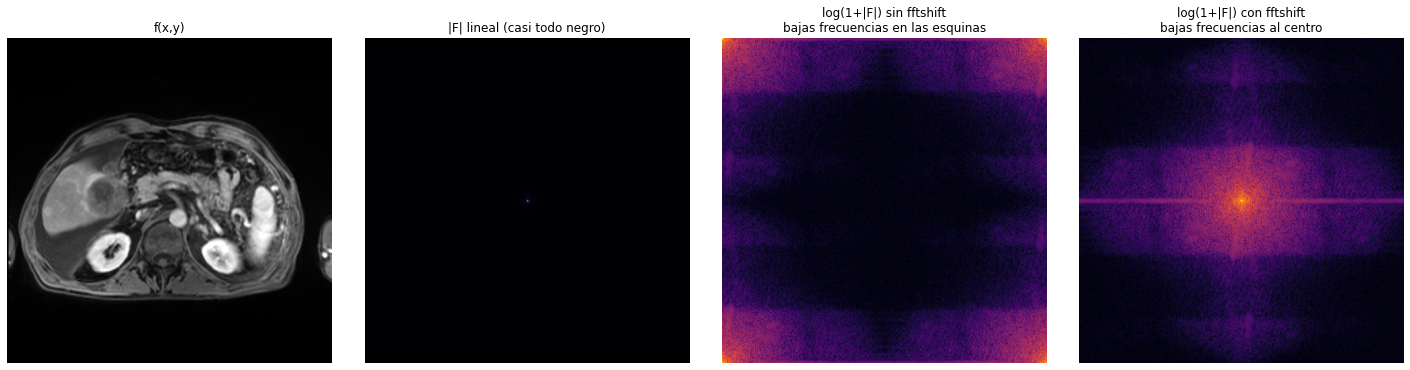

In [11]:
F = np.fft.fft2(img)            # espectro complejo, origen en (0,0)
F_shift = np.fft.fftshift(F)    # origen (frecuencia 0) al centro
M, N = img.shape

print("F(0,0)           =", F[0, 0].real.round(3))
print("M·N·media(f)     =", (M * N * img.mean()).round(3))
print("|F| máx / |F| mediana =", (np.abs(F).max() / np.median(np.abs(F))).round(1))

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("f(x,y)")
ax[1].imshow(np.abs(F_shift), cmap="inferno"); ax[1].set_title("|F| lineal (casi todo negro)")
ax[2].imshow(np.log1p(np.abs(F)), cmap="inferno"); ax[2].set_title("log(1+|F|) sin fftshift\nbajas frecuencias en las esquinas")
ax[3].imshow(np.log1p(np.abs(F_shift)), cmap="inferno"); ax[3].set_title("log(1+|F|) con fftshift\nbajas frecuencias al centro")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

Además de la magnitud está la **fase** $\angle F(u,v)$. A simple vista parece ruido, pero quise comprobar qué información guarda: reconstruí la imagen usando solo la magnitud y luego solo la fase. Con solo la magnitud no se reconoce nada, mientras que con solo la fase sí aparecen los contornos. O sea, la fase es la que guarda *dónde* están las cosas.

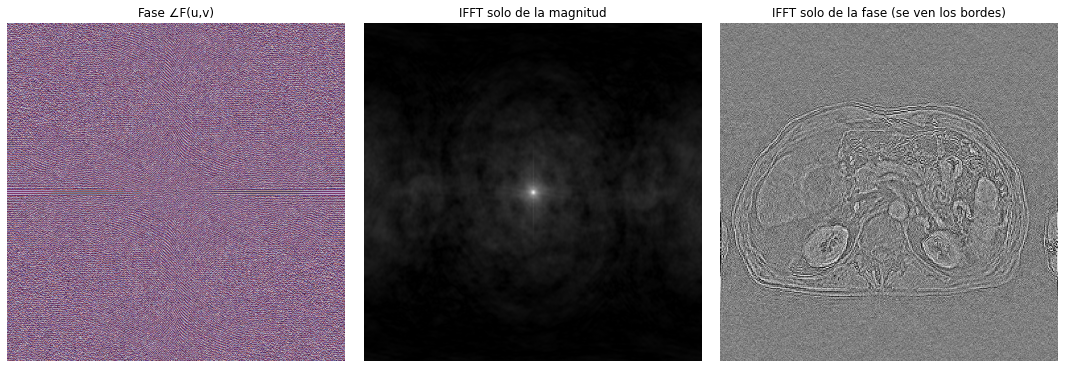

In [12]:
solo_magnitud = np.real(np.fft.ifft2(np.abs(F)))
solo_fase = np.real(np.fft.ifft2(np.exp(1j * np.angle(F))))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(np.angle(F_shift), cmap="twilight"); ax[0].set_title("Fase ∠F(u,v)")
ax[1].imshow(np.fft.fftshift(np.log1p(np.abs(solo_magnitud))), cmap="gray"); ax[1].set_title("IFFT solo de la magnitud")
ax[2].imshow(solo_fase, cmap="gray", vmin=np.percentile(solo_fase, 1), vmax=np.percentile(solo_fase, 99))
ax[2].set_title("IFFT solo de la fase (se ven los bordes)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Paso 3: Diseño del filtro pasa-altos

Primero calculamos la distancia de cada punto $(u,v)$ al centro del espectro:

$$D(u,v) = \sqrt{\left(u - \tfrac{M}{2}\right)^2 + \left(v - \tfrac{N}{2}\right)^2}$$

El **pasa-altos ideal** que pide la guía es una máscara circular que vale 0 dentro del radio de corte $D_0$ y 1 afuera:

$$H(u,v) = \begin{cases} 0 & \text{si } D(u,v) \le D_0 \\ 1 & \text{si } D(u,v) > D_0 \end{cases}$$

Aparte implementé otros dos filtros para comparar más adelante, que tienen una transición suave en vez del corte brusco:

$$H_{\text{Butterworth}}(u,v) = \dfrac{1}{1 + \left[\dfrac{D_0}{D(u,v)}\right]^{2n}}$$

$$H_{\text{Gauss}}(u,v) = 1 - e^{-\frac{D^2(u,v)}{2 D_0^2}}$$

Para la primera prueba usé $D_0 = 30$.

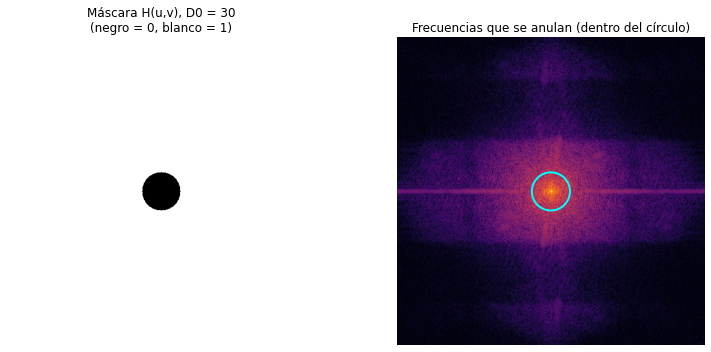

In [13]:
def distancias(shape):
    M, N = shape
    u = np.arange(M) - M // 2
    v = np.arange(N) - N // 2
    V, U = np.meshgrid(v, u)
    return np.sqrt(U**2 + V**2)

def pasa_altos_ideal(shape, D0):
    return (distancias(shape) > D0).astype(float)

def pasa_altos_butterworth(shape, D0, n=2):
    D = distancias(shape); D[D == 0] = 1e-9
    return 1.0 / (1.0 + (D0 / D) ** (2 * n))

def pasa_altos_gaussiano(shape, D0):
    D = distancias(shape)
    return 1.0 - np.exp(-(D**2) / (2 * D0**2))

D0 = 30
H = pasa_altos_ideal(img.shape, D0)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(H, cmap="gray", vmin=0, vmax=1); ax[0].set_title(f"Máscara H(u,v), D0 = {D0}\n(negro = 0, blanco = 1)")
ax[0].set_facecolor("k")
ax[1].imshow(np.log1p(np.abs(F_shift)), cmap="inferno")
ax[1].add_patch(plt.Circle((N // 2, M // 2), D0, fill=False, color="cyan", lw=2))
ax[1].set_title("Frecuencias que se anulan (dentro del círculo)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Paso 4: Aplicar el filtro y la transformada inversa

Multiplicamos el espectro centrado por la máscara. Algo que hay que tener cuidado es **deshacer el `fftshift` con `ifftshift` antes de la IFFT**, si no la imagen sale mal. Al final la parte imaginaria es prácticamente cero (es solo error de redondeo), por eso nos quedamos con la parte real.

Parte imaginaria máxima: 1.95e-16  (≈ 0)
Media original = 0.1527 | media filtrada = -3.98e-20  (se eliminó F(0,0))


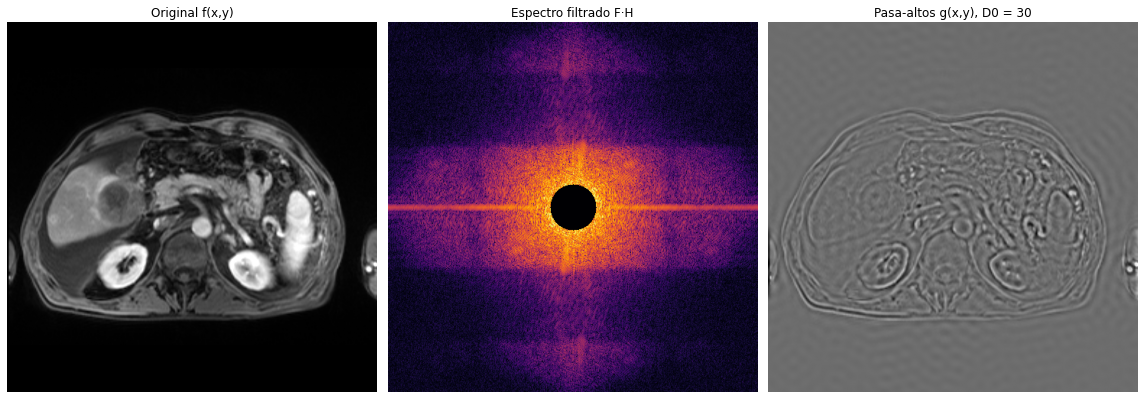

In [14]:
def filtrar(F_shift, H):
    G_shift = F_shift * H                # multiplicación punto a punto
    G = np.fft.ifftshift(G_shift)        # deshacer el centrado
    g = np.fft.ifft2(G)
    return g

g_complejo = filtrar(F_shift, H)
print(f"Parte imaginaria máxima: {np.abs(g_complejo.imag).max():.2e}  (≈ 0)")
filtrada = np.real(g_complejo)
print(f"Media original = {img.mean():.4f} | media filtrada = {filtrada.mean():.2e}  (se eliminó F(0,0))")

def visible(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-12)

fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Original f(x,y)")
ax[1].imshow(np.log1p(np.abs(F_shift * H)), cmap="inferno"); ax[1].set_title("Espectro filtrado F·H")
ax[2].imshow(visible(filtrada), cmap="gray"); ax[2].set_title(f"Pasa-altos g(x,y), D0 = {D0}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### Comprobación
Si en lugar de la máscara uso $H = 1$ (no filtrar nada), la IFFT tendría que devolver la misma imagen. El error salió del orden de $10^{-16}$, entonces el proceso de ida y vuelta está bien hecho.

In [15]:
recuperada = np.real(filtrar(F_shift, np.ones_like(H)))
print(f"Error máximo de reconstrucción: {np.abs(recuperada - img).max():.2e}")

Error máximo de reconstrucción: 6.66e-16


## Paso 5: Análisis de resultados

### Efecto del radio de corte $D_0$
Probamos con $D_0 = 5,\ 15,\ 30,\ 60$ y $100$. Para cada uno calculé también qué porcentaje de la energía del espectro deja pasar el filtro:

$$E = \dfrac{\sum |F \cdot H|^2}{\sum |F|^2} \times 100$$

D0 =   5  -> energía conservada =  18.87 %
D0 =  15  -> energía conservada =   7.02 %
D0 =  30  -> energía conservada =   3.13 %
D0 =  60  -> energía conservada =   0.79 %
D0 = 100  -> energía conservada =   0.12 %


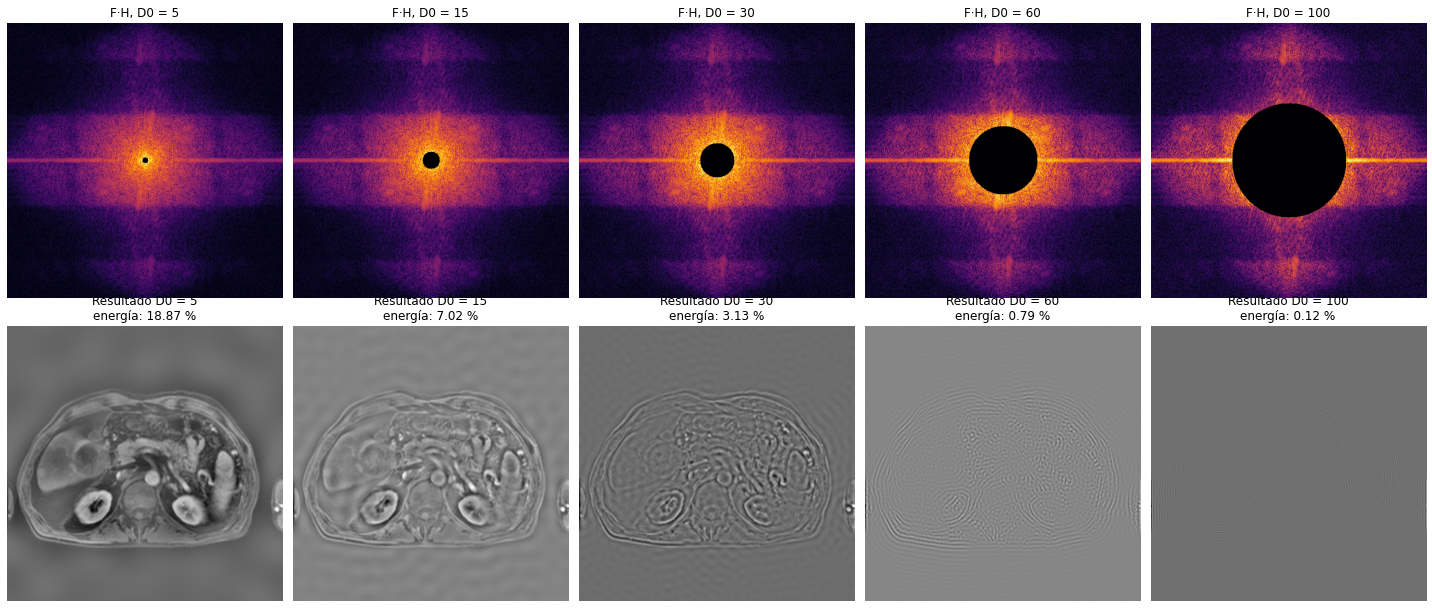

In [16]:
radios = [5, 15, 30, 60, 100]
energia_total = np.sum(np.abs(F_shift)**2)

fig, ax = plt.subplots(2, len(radios), figsize=(4 * len(radios), 8.5))
for i, d0 in enumerate(radios):
    Hi = pasa_altos_ideal(img.shape, d0)
    gi = np.real(filtrar(F_shift, Hi))
    energia = np.sum(np.abs(F_shift * Hi)**2) / energia_total * 100
    print(f"D0 = {d0:3d}  -> energía conservada = {energia:6.2f} %")
    ax[0, i].imshow(np.log1p(np.abs(F_shift * Hi)), cmap="inferno"); ax[0, i].set_title(f"F·H, D0 = {d0}")
    ax[1, i].imshow(visible(gi), cmap="gray"); ax[1, i].set_title(f"Resultado D0 = {d0}\nenergía: {energia:.2f} %")
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.tight_layout(); plt.show()

**Lo que observamos con cada $D_0$:**

- **$D_0 = 5$:** el círculo es muy pequeño y casi solo quita la componente DC y las frecuencias más bajas. Todavía se reconocen todos los órganos, pero las zonas parejas (como el interior del hígado) se ven más planas y los bordes resaltan. Aún pasa el 18.87 % de la energía.
- **$D_0 = 15$:** desaparece casi toda la información de intensidad y quedan sobre todo los contornos: los riñones, la vértebra, la aorta y el borde de la lesión del hígado se ven bien marcados.
- **$D_0 = 30$:** solo quedan los bordes más finos y empiezan a notarse unas ondas alrededor de los contornos (ringing). Pasa solo el 3.13 % de la energía.
- **$D_0 = 60$ y $100$:** queda menos del 1 % de la energía. Ya casi no se reconoce nada, lo que se ve es principalmente ruido y anillos.

Con esto se confirma lo que dice la guía: con un $D_0$ pequeño pasan todavía frecuencias medias y la imagen mantiene su forma, y mientras más grande es $D_0$ el filtro resalta los detalles de forma más agresiva, hasta que se queda con puro ruido. Para esta imagen, valores entre 15 y 30 son los que mejor muestran los bordes.

### Perfil de intensidad de la fila central
Comparando la fila del medio se ve que, después del filtro, las zonas planas se van a cero y solo quedan picos en los bordes. Con $D_0$ más grande los picos son más chicos y aparecen oscilaciones.

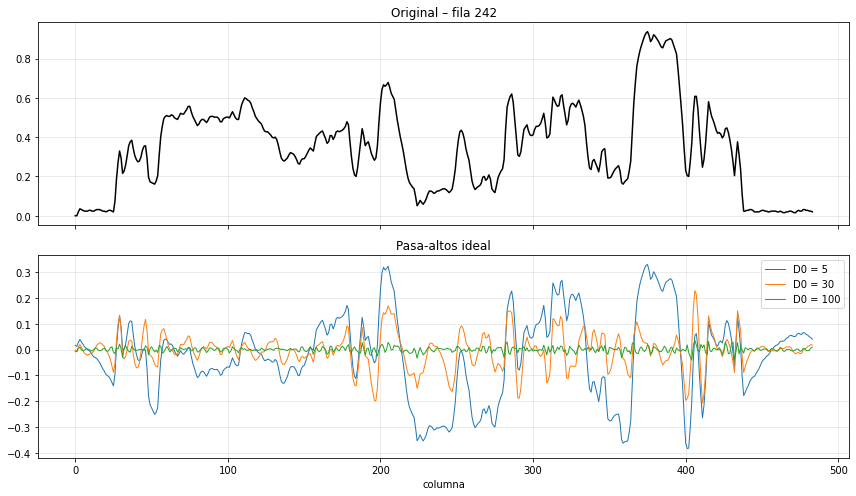

In [17]:
fila = img.shape[0] // 2
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(img[fila], "k"); ax[0].set_title(f"Original – fila {fila}"); ax[0].grid(alpha=.3)
for d0 in [5, 30, 100]:
    ax[1].plot(np.real(filtrar(F_shift, pasa_altos_ideal(img.shape, d0)))[fila], lw=1, label=f"D0 = {d0}")
ax[1].set_title("Pasa-altos ideal"); ax[1].legend(); ax[1].grid(alpha=.3); ax[1].set_xlabel("columna")
plt.tight_layout(); plt.show()

### Ideal vs Butterworth vs Gaussiano
El filtro ideal tiene un corte brusco y por eso produce **ringing** (anillos alrededor de los bordes). Esto pasa porque en el espacio un círculo de este tipo equivale a convolucionar con una función tipo sinc, que tiene oscilaciones. Con Butterworth y Gaussiano, que bajan de forma suave, los anillos casi desaparecen.

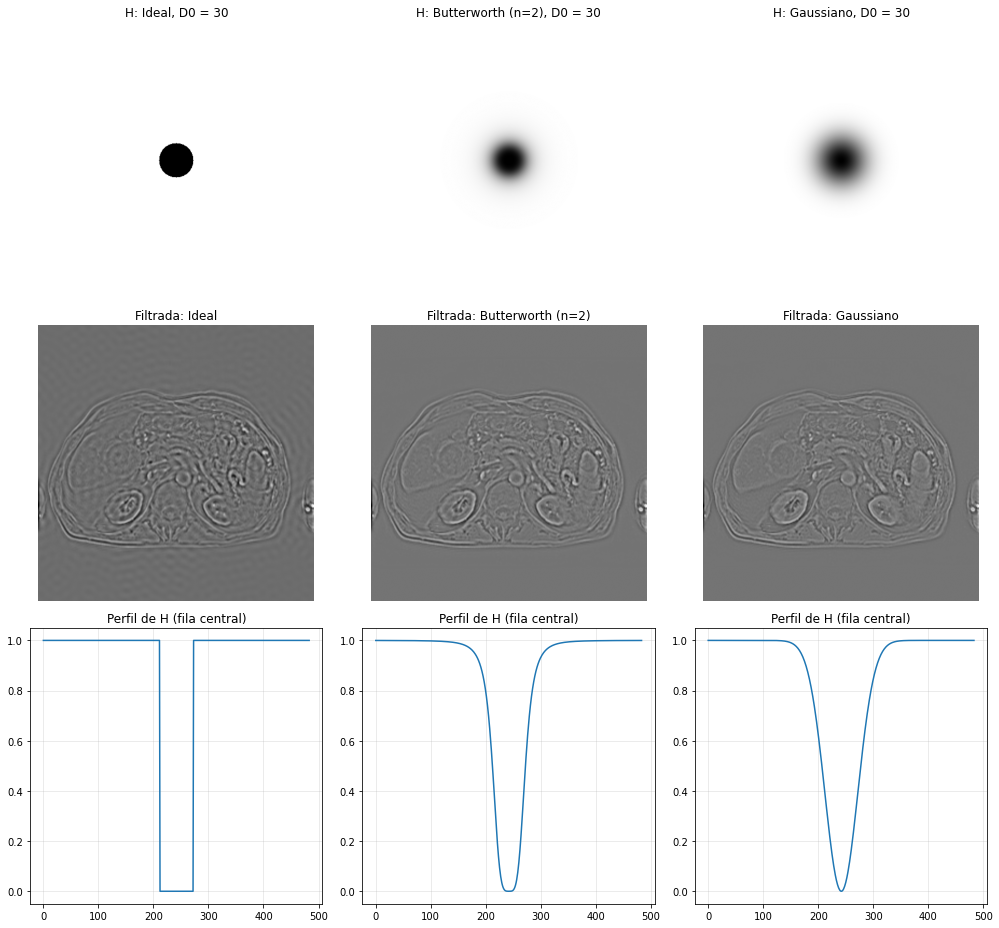

In [18]:
filtros = {
    "Ideal": pasa_altos_ideal(img.shape, D0),
    "Butterworth (n=2)": pasa_altos_butterworth(img.shape, D0, 2),
    "Gaussiano": pasa_altos_gaussiano(img.shape, D0),
}
fig, ax = plt.subplots(3, 3, figsize=(14, 13))
for i, (nom, Hf) in enumerate(filtros.items()):
    gf = np.real(filtrar(F_shift, Hf))
    ax[0, i].imshow(Hf, cmap="gray", vmin=0, vmax=1); ax[0, i].set_title(f"H: {nom}, D0 = {D0}")
    ax[1, i].imshow(visible(gf), cmap="gray"); ax[1, i].set_title(f"Filtrada: {nom}")
    ax[2, i].plot(Hf[M // 2]); ax[2, i].set_ylim(-0.05, 1.05); ax[2, i].grid(alpha=.3)
    ax[2, i].set_title("Perfil de H (fila central)")
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.tight_layout(); plt.show()

### Realce de bordes (*high-boost*)
Para aprovechar el filtro en algo práctico, sumamos la imagen pasa-altos a la original:
$$f_{\text{realzada}} = f + k \cdot g$$
con $k = 1.5$. La imagen final se ve más nítida, sobre todo en los contornos de los riñones y de la lesión.

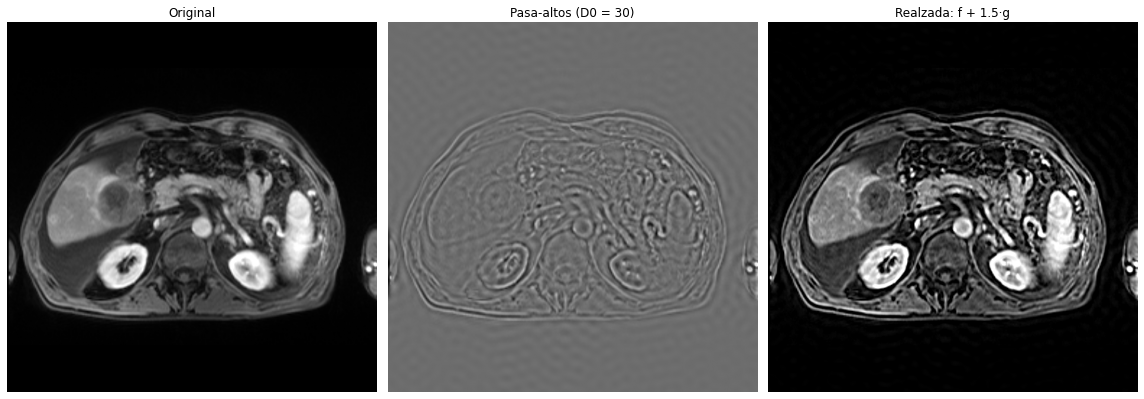

In [19]:
k = 1.5
realzada = np.clip(img + k * filtrada, 0, 1)
fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Original")
ax[1].imshow(visible(filtrada), cmap="gray"); ax[1].set_title(f"Pasa-altos (D0 = {D0})")
ax[2].imshow(realzada, cmap="gray"); ax[2].set_title(f"Realzada: f + {k}·g")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### Relación entre las dos partes
Me pareció interesante ver los kernels de gradiente de la parte 04.01 en frecuencia. Calculando la FFT de $K_x$ se ve que su respuesta $|H(u,v)|$ vale **cero en la columna central** ($v = 0$), o sea que eliminan la componente DC y los cambios lentos, igual que un pasa-altos. En Prewitt y Sobel además baja en las frecuencias más altas por el suavizado, así que en realidad se comportan como **pasa-banda**, lo que explica por qué les afectó menos el ruido.

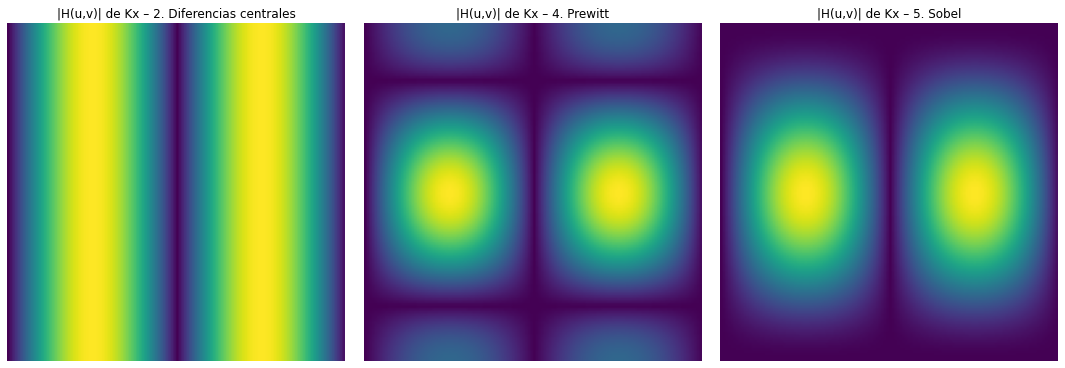

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for i, nombre in enumerate(["2. Diferencias centrales", "4. Prewitt", "5. Sobel"]):
    kx = KERNELS[nombre][0]
    Hk = np.fft.fftshift(np.abs(np.fft.fft2(kx, s=(128, 128))))
    ax[i].imshow(Hk, cmap="viridis"); ax[i].set_title(f"|H(u,v)| de Kx – {nombre}"); ax[i].axis("off")
plt.tight_layout(); plt.show()

## Conclusiones
1. Al aplicar la TF y centrar el espectro con `fftshift`, la mayor parte de la energía queda en el centro (bajas frecuencias), porque la mayoría de la imagen son zonas con intensidad parecida.
2. El filtro pasa-altos elimina $F(0,0)$, por eso la media de la imagen filtrada sale prácticamente 0 y las zonas uniformes quedan grises. Lo que sobrevive son los contornos: la silueta del cuerpo, los riñones, la vértebra, la aorta, el borde de la lesión del hígado y las asas intestinales.
3. El radio $D_0$ controla qué tanto se elimina. Con $D_0$ chico la imagen todavía se reconoce con los bordes realzados; con $D_0$ grande (60 o más) queda menos del 1 % de la energía y lo que se ve es solo ruido y detalles muy finos.
4. El filtro ideal genera ringing por su corte brusco. Los filtros Butterworth y Gaussiano dan un resultado más limpio.
5. Sumando la parte de altas frecuencias a la original (*high-boost*) se consigue una imagen más nítida, que puede ser útil para resaltar estructuras en imágenes médicas.
6. Los operadores de gradiente de la parte 04.01 también se pueden ver como filtros en frecuencia (anulan la componente DC), lo que muestra que filtrar en el espacio y en frecuencia están conectados por el teorema de convolución.